# 어텐션 직관

**이 노트북에서 할 일**

1. 숫자 세 개짜리 작은 벡터로 어텐션 점수, 비중, 새 벡터를 차례로 계산합니다.
2. 질문 벡터를 B에서 A로 바꿔, 가장 큰 비중이 어느 조각으로 옮겨 가는지 확인합니다.
3. 실제 언어 모델의 어텐션 비중을 꺼내, 교재 예와 무엇이 다른지 봅니다.

**준비물** — API 키는 필요 없습니다. 인터넷 서비스의 모델을 부르지 않고, 내 컴퓨터에서 작은 언어 모델을 실행합니다.
그래서 비용은 들지 않습니다. 모델 계산은 모두 2번 합니다.

실행 시간은 2분 안팎입니다. 첫 실행에서는 Hugging Face 사이트에서 모델 파일을 내려받으므로 인터넷 연결이 필요합니다.
교재 실행 컴퓨터에서 받은 모델 파일은 합쳐 약 1GB(954MiB)였습니다.
노트북과 같은 계산을 스크립트로 실행했을 때 Python이 쓴 메모리는 최대 약 3.4GB였습니다.

**강의와 실습 범위** — 강의 시간에는 2~5번(교재 예의 점수·비중·새 벡터)과 7·9번 결과를 설명합니다.
6·8·10번은 셀을 함께 실행하고, 결과 읽기는 실습 시간에 이어서 읽습니다. 끝의 「원리 더 알아보기」도 실습 시간에 읽습니다.

**기준 버전** — 실습 폴더에 고정한 transformers 4.56.2와 torch 2.8.0을 씁니다.
모델은 `Qwen/Qwen2.5-0.5B-Instruct`이고, 판 번호(revision)를 `7ae557604adf67be50417f59c2c2f167def9a775`로 고정해 받습니다.

교재 출력은 Linux의 Python 3.12.13과 CPU용 torch(2.8.0+cpu)로 만들었습니다. 다른 버전, GPU, Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part1/ch05-llm-principles`에서 01절과 같은 `.venv` 커널을 고른 뒤 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

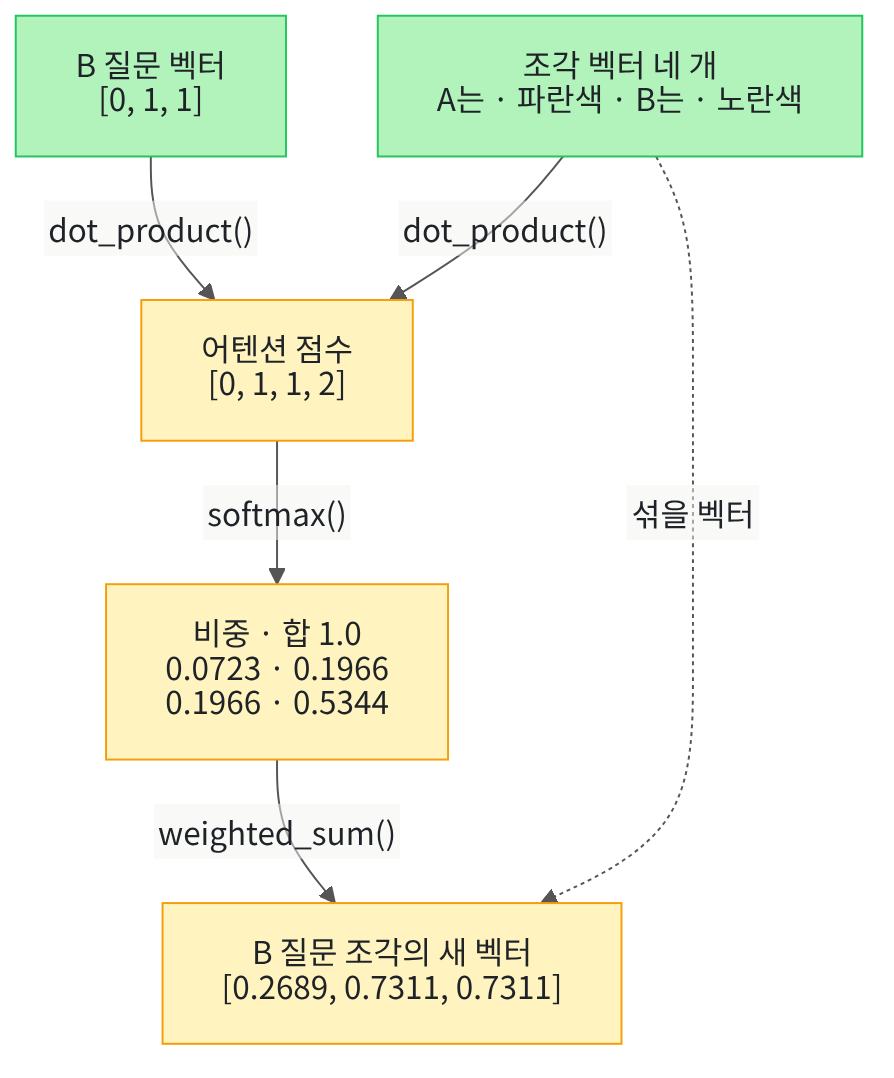

위에서 아래로 읽습니다. 초록 상자는 교재에서 정한 작은 벡터이고, 노란 상자는 출력으로 확인하는 값입니다.
화살표 위 글자는 이 노트북에서 직접 만드는 함수입니다. 점수를 비중으로 바꾸고, 비중대로 조각 벡터를 섞어 새 벡터를 만듭니다.

## 1. 준비

이 절은 파일을 읽거나 만들지 않습니다. 준비 셀에서는 계산에 쓸 모듈과 패키지를 불러오고 버전을 확인합니다.

표준 라이브러리 모듈 `math`는 02절에서 제곱근을 구할 때 쓴 기능 묶음입니다. 이 절에서는 거듭제곱 함수를 씁니다.
패키지 transformers는 01절에서 토큰화기를 불러온 패키지이고, 이번에는 언어 모델도 함께 불러옵니다.
함수 `warnings.filterwarnings()` 줄은 01절처럼 진행 표시 위젯이 없다는 경고 한 줄을 끕니다. 계산 결과와 관계없는 경고입니다.

In [1]:
# 계산에 쓸 math 모듈과 transformers 패키지를 불러오고 버전을 확인합니다
import math
import warnings

# 진행 표시 위젯이 없다는 경고(TqdmWarning)는 계산과 관계없어 화면에 내지 않습니다
warnings.filterwarnings("ignore", message="IProgress not found")

import transformers
from transformers import AutoModelForCausalLM, AutoTokenizer

print("transformers 버전:", transformers.__version__)

transformers 버전: 4.56.2


**결과 읽기** — 출력 줄은 `transformers 버전: 4.56.2`입니다. 준비물에 적은 기준 버전과 같습니다.

## 2. 어텐션 점수 — 질문 벡터와 조각 벡터의 점곱

어텐션(attention)은 한 토큰의 벡터를 새로 만들 때, 다른 토큰의 벡터를 얼마만큼씩 섞을지 정하는 계산입니다.
친구가 「B 상품 색이 뭐였지?」라고 물으면, 우리는 메모에서 B가 적힌 쪽을 더 눈여겨봅니다. 어텐션은 이 눈여겨보는 정도를 숫자로 계산합니다.

먼저 숫자 세 개짜리 작은 벡터로 계산을 따라갑니다. 첫 단계는 02절에서 배운 점곱입니다.
두 벡터의 방향이 비슷할수록 점곱이 커지므로, 질문 벡터와 조각 벡터의 점곱을 어텐션 점수로 씁니다.
아래 셀은 02절과 같은 함수 `dot_product()`를 다시 정의합니다. 노트북은 서로 독립이라, 02절에서 만든 함수가 이 노트북에는 없습니다.

In [2]:
# 두 벡터의 점곱(같은 자리 숫자끼리 곱해 모두 더한 값)을 반환하는 함수를 정의합니다
def dot_product(first, second):
    total = 0
    # 반복 번호 i로 두 벡터의 같은 자리 숫자를 짝지어 곱하고 더합니다
    for i in range(len(first)):
        total = total + first[i] * second[i]
    return total

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

조각 네 개는 문장 「상품 A는 파란색이고 상품 B는 노란색입니다.」에서 고른 낱말입니다.
벡터의 숫자 세 개는 차례로 A와 관련된 정도, B와 관련된 정도, 색을 나타내는 정도로 정했습니다.
손으로 계산을 따라가려고 교재에서 정한 숫자입니다. 02절에서 봤듯이 실제 모델의 벡터는 숫자 하나만 보고 뜻을 읽을 수 없습니다.

「B의 색은?」을 묻는 조각의 질문 벡터는 `[0, 1, 1]`로 둡니다. B 자리와 색 자리에만 1이 있습니다.
실행 전에 예상합니다. 노란색 조각은 B와 색을 모두 가져, 점수가 가장 클 것입니다.

In [3]:
# 조각 네 개의 교재용 벡터와 B의 색을 묻는 질문 벡터로, 조각마다 어텐션 점수를 계산합니다
word_pieces = ["A는", "파란색", "B는", "노란색"]
# 숫자 세 개는 차례로 A와 관련된 정도, B와 관련된 정도, 색을 나타내는 정도입니다
piece_vectors = [[1, 0, 0], [1, 0, 1], [0, 1, 0], [0, 1, 1]]
question_b = [0, 1, 1]
# 질문 벡터와 조각 벡터의 점곱이 그 조각의 어텐션 점수입니다
scores_b = []
for vector in piece_vectors:
    scores_b.append(dot_product(question_b, vector))
print("조각:", word_pieces)
print("B 질문의 점수:", scores_b)

조각: ['A는', '파란색', 'B는', '노란색']
B 질문의 점수: [0, 1, 1, 2]


**결과 읽기** — 출력 줄은 `B 질문의 점수: [0, 1, 1, 2]`입니다. 예상대로 노란색 조각의 점수가 가장 큽니다.

조각 파란색은 색 자리만, 조각 `B는`은 B 자리만 질문 벡터와 겹쳐 1점입니다. 조각 `A는`은 겹치는 자리가 없어 0점입니다.

## 3. 소프트맥스 — 점수를 비중으로 바꾸기

점수를 그대로 섞는 양으로 쓰기는 어렵습니다. 합이 정해져 있지 않고, 0점이나 음수 점수도 나올 수 있습니다.
그래서 점수를 모두 0보다 크고 합이 1인 비중(weight)으로 바꿉니다. 이 계산을 소프트맥스(softmax)라고 부릅니다.

소프트맥스는 두 단계입니다. 점수마다 수 e(약 2.718)를 점수만큼 거듭제곱하고, 그 값을 거듭제곱의 합으로 나눕니다.
점수가 1 크면 거듭제곱은 약 2.7배가 되어, 큰 점수가 더 도드라집니다.
함수 `math.exp(수)`는 e를 그 수만큼 거듭제곱한 값을 반환합니다. 이 셀은 함수를 정의만 합니다.

In [4]:
# 점수 목록을 합이 1인 비중 목록으로 바꾸는 소프트맥스 함수를 정의합니다
def softmax(scores):
    # 점수마다 e의 거듭제곱을 구하고, 그 합을 함께 셉니다
    powers = []
    total = 0
    for score in scores:
        power = math.exp(score)
        powers.append(power)
        total = total + power
    # 거듭제곱을 합으로 나누면 모두 0보다 크고 합이 1인 비중이 됩니다
    weights = []
    for power in powers:
        weights.append(power / total)
    return weights

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다. 다음 셀에서 2절의 점수로 호출합니다.

실행 전에 예상합니다. 점수 2의 거듭제곱은 약 7.389입니다. 네 거듭제곱의 합은 1 + 2.718 + 2.718 + 7.389로 약 13.826입니다.
노란색 조각의 비중은 7.389 ÷ 13.826으로 0.53쯤일 것입니다.

In [5]:
# B 질문의 점수를 비중으로 바꾸고, 조각마다 비중과 비중의 합을 출력합니다
weights_b = softmax(scores_b)
weight_total = 0
print("조각마다 점수와 비중:")
for number in range(len(word_pieces)):
    weight_total = weight_total + weights_b[number]
    print(word_pieces[number], "| 점수", scores_b[number], "| 비중", round(weights_b[number], 4))
print("비중의 합:", round(weight_total, 4))

조각마다 점수와 비중:
A는 | 점수 0 | 비중 0.0723
파란색 | 점수 1 | 비중 0.1966
B는 | 점수 1 | 비중 0.1966
노란색 | 점수 2 | 비중 0.5344
비중의 합: 1.0


**결과 읽기** — 라벨 줄 아래 네 줄의 비중은 차례로 `0.0723`, `0.1966`, `0.1966`, `0.5344`입니다. 마지막 줄은 `비중의 합: 1.0`입니다.

예상대로 노란색 조각이 전체 비중의 절반 넘게 가져갔습니다. 점수가 1로 같은 파란색과 `B는` 조각은 비중도 같습니다.
점수 0인 조각 `A는`도 비중이 0이 아니라 작은 양수입니다.

## 4. 가중합 — 비중대로 섞어 새 벡터 만들기

비중이 정해지면 조각 벡터를 그 비중대로 섞습니다. 자리마다 비중과 조각 벡터의 숫자를 곱해 모두 더한 값을 가중합(weighted sum)이라고 부릅니다.
주스 네 가지를 서로 다른 양으로 부어 한 컵에 섞는 일과 비슷합니다. 어텐션은 이렇게 섞은 벡터를 질문 조각의 새 벡터로 씁니다.

아래 함수 `weighted_sum()`은 바깥 `for`로 벡터의 자리를 하나씩 고릅니다. 안쪽 `for`는 조각마다 비중을 곱해 더합니다.
두 겹 `for`는 01절에서 문장을 이어 붙일 때 썼습니다. 이 셀은 함수를 정의만 합니다.

In [6]:
# 비중 목록대로 여러 벡터를 섞은 가중합 벡터를 반환하는 함수를 정의합니다
def weighted_sum(weights, vectors):
    result = []
    # 바깥 반복은 벡터의 자리(0, 1, 2번)를 하나씩 고릅니다
    for position in range(len(vectors[0])):
        total = 0
        # 안쪽 반복은 조각마다 비중과 그 자리 숫자를 곱해 더합니다
        for i in range(len(vectors)):
            total = total + weights[i] * vectors[i][position]
        result.append(total)
    return result

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

다음 셀은 B 질문의 비중으로 새 벡터를 만듭니다. 비교를 위해 네 조각에 같은 비중 0.25를 준 경우도 계산합니다.
02절 임베딩 모델은 토큰마다 만든 숫자 목록을 평균으로 합쳤는데, 같은 비중으로 섞는 가중합이 바로 평균입니다.
실행 전에 예상합니다. 노란색 조각 `[0, 1, 1]`의 비중이 가장 크니, 새 벡터는 B 자리와 색 자리의 숫자가 A 자리보다 클 것입니다.

In [7]:
# B 질문의 비중대로 조각 벡터를 섞고, 같은 비중으로 섞은 평균과 비교합니다
new_vector_b = weighted_sum(weights_b, piece_vectors)
rounded_b = []
for value in new_vector_b:
    rounded_b.append(round(value, 4))
print("B 질문 조각의 새 벡터:", rounded_b)
# 02절 임베딩 모델처럼 모든 조각에 같은 비중을 주면 평균이 됩니다
equal_weights = [0.25, 0.25, 0.25, 0.25]
average_vector = weighted_sum(equal_weights, piece_vectors)
print("같은 비중으로 섞은 평균:", average_vector)

B 질문 조각의 새 벡터: [0.2689, 0.7311, 0.7311]
같은 비중으로 섞은 평균: [0.5, 0.5, 0.5]


**결과 읽기** — 새 벡터는 `B 질문 조각의 새 벡터: [0.2689, 0.7311, 0.7311]`입니다. 평균은 `같은 비중으로 섞은 평균: [0.5, 0.5, 0.5]`입니다.

예상대로 새 벡터는 B 자리와 색 자리가 0.7311로 A 자리보다 큽니다. 평균은 세 자리가 모두 같아, 무엇을 물었는지 드러나지 않습니다.
어텐션은 질문에 따라 섞는 양을 달리해, 질문 조각의 벡터에 B의 색 쪽 정보를 더 많이 담았습니다.

## 5. 값 바꿔 보기 — 질문 벡터를 A로 바꾸기

바꾸는 값은 질문 벡터 하나입니다. 「A의 색은?」을 묻도록 A 자리와 색 자리에 1을 둔 `[1, 0, 1]`로 바꿉니다.
조각 벡터와 함수 세 개는 그대로 씁니다.

실행 전에 예상합니다. 가장 큰 비중 0.5344가 노란색 조각에서 파란색 조각으로 옮겨 갈 것입니다.

In [8]:
# 질문 벡터만 A의 색을 묻도록 바꿔 점수와 비중을 다시 계산하고, B 질문과 나란히 봅니다
question_a = [1, 0, 1]
scores_a = []
for vector in piece_vectors:
    scores_a.append(dot_product(question_a, vector))
weights_a = softmax(scores_a)
print("A 질문의 점수:", scores_a)
print("조각 | B 질문 비중 | A 질문 비중")
for number in range(len(word_pieces)):
    print(word_pieces[number], "|", round(weights_b[number], 4), "|", round(weights_a[number], 4))

A 질문의 점수: [1, 2, 0, 1]
조각 | B 질문 비중 | A 질문 비중
A는 | 0.0723 | 0.1966
파란색 | 0.1966 | 0.5344
B는 | 0.1966 | 0.0723
노란색 | 0.5344 | 0.1966


**결과 읽기** — 점수는 `A 질문의 점수: [1, 2, 0, 1]`입니다. 표의 파란색 줄은 `파란색 | 0.1966 | 0.5344`, 노란색 줄은 `노란색 | 0.5344 | 0.1966`입니다.

예상대로 가장 큰 비중이 노란색 조각에서 파란색 조각으로 옮겨 갔습니다. 조각 벡터는 그대로이고 질문 벡터만 바꿨는데, 비중이 달라졌습니다.
여기까지는 교재에서 정한 숫자로 본 계산입니다. 다음 절부터는 실제 언어 모델이 계산한 비중을 꺼내 봅니다.

## 6. 실제 언어 모델 준비

모델은 Qwen2.5-0.5B-Instruct입니다. 내 컴퓨터에서 실행할 수 있는 작은 언어 모델로, 04절 이후 절에서도 씁니다.
클래스 `AutoModelForCausalLM`은 앞 토큰들에 이어질 다음 토큰을 고르는 언어 모델을 불러옵니다.
01절 `AutoTokenizer`처럼 `from_pretrained(모델 이름, revision=판 번호)`로 만듭니다.

인자 `attn_implementation="eager"`는 어텐션 비중을 꺼내 볼 수 있는 계산 방식을 고릅니다.
설치한 transformers 4.56.2 소스에서, 다른 계산 방식(sdpa)은 비중을 반환하지 않는다고 확인했습니다. 이 인자를 뺀 실행은 이번에 하지 않았습니다.

언어 모델은 층(layer)을 여러 개 쌓아 차례로 계산하고, 층마다 어텐션을 여러 번 나란히 계산합니다. 나란히 계산하는 한 단위를 머리(head)라고 부릅니다.
실행 전에 예상합니다. 작은 모델이니 층과 머리가 몇 개뿐일 것입니다.

In [9]:
# 언어 모델과 토큰화기를 고정 판 번호로 받고, 층 수와 층마다 머리 수를 확인합니다
model_name = "Qwen/Qwen2.5-0.5B-Instruct"
model_revision = "7ae557604adf67be50417f59c2c2f167def9a775"
tokenizer = AutoTokenizer.from_pretrained(model_name, revision=model_revision)
# attn_implementation="eager"는 층마다 어텐션 비중을 꺼내 볼 수 있는 계산 방식입니다
model = AutoModelForCausalLM.from_pretrained(
    model_name,
    revision=model_revision,
    attn_implementation="eager",
)
print("층 수:", model.config.num_hidden_layers)
print("층마다 머리 수:", model.config.num_attention_heads)

층 수: 24
층마다 머리 수: 14


**결과 읽기** — 출력 줄은 `층 수: 24`와 `층마다 머리 수: 14`입니다. 예상보다 층과 머리가 많습니다.

이 모델은 층 24개를 차례로 거치고, 층마다 어텐션을 14번 나란히 계산합니다.
이 노트북의 출력은 2026-09-16에 이 모델과 판 번호로 실행한 결과입니다.

## 7. 문장을 조각으로 나누고 비중 표 받기

비교할 문장은 2절 문장 뒤에 「상품 B는」을 이어 붙인 글입니다. 모델은 이 글 다음에 올 조각을 고르려고 계산합니다.
01절처럼 메서드 `encode()`로 ID 목록을 만들고, ID를 하나씩 `decode()`로 되돌려 조각 글자를 봅니다.

실행 전에 예상합니다. 01절 GPT-2 토큰화기는 한글 한 글자를 여러 조각으로 나눴지만, 이 토큰화기는 조각이 더 적을 것입니다.

In [10]:
# 문장을 토큰 ID로 바꾸고, ID마다 되돌린 조각 글자를 목록에 모읍니다
sentence = "상품 A는 파란색이고 상품 B는 노란색입니다. 상품 B는"
id_list = tokenizer.encode(sentence)
token_pieces = []
for token_id in id_list:
    token_pieces.append(tokenizer.decode([token_id]))
print("토큰 수:", len(id_list))
print("조각 목록:", token_pieces)

토큰 수: 21
조각 목록: ['상', '품', ' A', '는', ' 파', '란', '색', '이고', ' 상', '품', ' B', '는', ' 노', '란', '색', '입니다', '.', ' 상', '품', ' B', '는']


**결과 읽기** — 출력 줄은 `토큰 수: 21`입니다. 조각 목록에서 파란색은 `' 파'`, `'란'`, `'색'` 세 조각으로 나뉘었습니다.

조각 앞의 공백은 원래 글의 띄어쓰기입니다. 조각은 `'이고'`처럼 두세 글자이거나 한 글자였습니다. 이 문장에서는 01절 GPT-2 토큰화기처럼 한 글자를 여러 조각으로 나눈 곳이 없었습니다.
다만 교재를 만들 때 확인하니 「빨간색」의 「 빨」은 이 토큰화기에서도 조각 세 개로 나뉘어, 이 문장에는 넣지 않았습니다.
조각 번호는 0부터 세므로, 마지막 조각은 20번 `' 는'`입니다.

모델 객체를 함수처럼 부르면 ID 목록으로 한 번 계산합니다. 인자 `output_attentions=True`를 주면 층마다 어텐션 비중 표를 함께 반환합니다.
메서드 `encode()`에 인자 `return_tensors="pt"`를 주면 ID 목록을 PyTorch의 숫자 표로 반환합니다.
이런 숫자 표를 텐서(tensor)라고 부릅니다. 02절의 NumPy 배열처럼 속성 `shape`로 모양을 봅니다.

실행 전에 예상합니다. 비중 표는 층 수만큼 24개이고, 한 표에는 조각 21개와 21개가 짝지어 있을 것입니다.

In [11]:
# 문장을 텐서로 바꿔 모델을 한 번 계산하고, 층마다 받은 어텐션 비중 표의 모양을 봅니다
# return_tensors="pt"를 주면 ID 목록을 PyTorch 텐서로 반환합니다
input_ids = tokenizer.encode(sentence, return_tensors="pt")
# output_attentions=True를 주면 계산 결과에 층마다 어텐션 비중 표가 함께 들어 있습니다
outputs = model(input_ids=input_ids, output_attentions=True)
print("비중 표 수:", len(outputs.attentions))
print("한 층 표의 모양:", outputs.attentions[0].shape)

비중 표 수: 24
한 층 표의 모양: torch.Size([1, 14, 21, 21])


**결과 읽기** — 출력 줄은 `비중 표 수: 24`와 `한 층 표의 모양: torch.Size([1, 14, 21, 21])`입니다.

모양의 네 수는 차례로 문장 수 1, 머리 수 14, 조각 수 21, 조각 수 21입니다. 한 층에 조각 21개 × 21개 표가 머리마다 한 장씩, 14장 있습니다.
표의 한 줄은 조각 하나가 다른 조각들에 준 비중입니다. 3절에서 계산한 `weights_b`가 이 표의 한 줄과 같은 역할입니다.

## 8. 머리 14개를 평균해 한 줄 읽기

한 조각의 줄은 머리마다 따로 있습니다. 여기서는 머리 14개의 비중을 자리마다 평균 내어 한 줄로 봅니다.

메서드 `tolist()`는 텐서를 Python 목록으로 바꿉니다. 층 표의 `[0]`은 첫 문장이고, 그 안에 머리 14개의 표가 있습니다.
아래 함수는 층 표 하나와 줄 번호를 받아, 머리 평균 줄을 목록으로 반환합니다. 이 셀은 함수를 정의만 합니다.

In [12]:
# 층 표 하나에서 줄 하나를 골라, 머리 14개의 비중을 자리마다 평균 낸 목록을 반환합니다
def average_heads(layer_table, row_number):
    # 첫 문장(0번)의 표를 Python 목록으로 바꾸면 머리 수만큼의 표가 됩니다
    heads = layer_table[0].tolist()
    averages = []
    for position in range(len(heads[0][row_number])):
        total = 0
        # 머리마다 같은 줄, 같은 자리의 비중을 더해 머리 수로 나눕니다
        for head in heads:
            total = total + head[row_number][position]
        averages.append(total / len(heads))
    return averages

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

먼저 0번 층에서 2번 조각 `' A'`의 줄을 봅니다. 다음 조각을 고르는 모델은 뒤에 올 글을 보지 않고 계산합니다.
실행 전에 예상합니다. 2번 조각의 줄은 0~2번 자리에만 비중이 있고, 3번 자리부터는 0일 것입니다.

In [13]:
# 0번 층에서 2번 조각의 줄을 머리 평균으로 구하고, 앞 여섯 자리를 반올림해 봅니다
third_row = average_heads(outputs.attentions[0], 2)
rounded_row = []
for weight in third_row:
    rounded_row.append(round(weight, 4))
print("0번 층, 2번 조각 줄의 앞 여섯 자리:", rounded_row[0:6])

0번 층, 2번 조각 줄의 앞 여섯 자리: [0.1912, 0.416, 0.3928, 0.0, 0.0, 0.0]


**결과 읽기** — 출력 줄 끝의 목록은 `[0.1912, 0.416, 0.3928, 0.0, 0.0, 0.0]`입니다.

예상대로 0~2번 자리의 비중만 0보다 크고, 세 값을 더하면 1입니다. 3번 자리부터는 `0.0`입니다.
2번 조각은 자기 자신과 앞 조각 두 개에만 비중을 나눴습니다.

이번에는 마지막 층에서 마지막 조각(20번 `' 는'`)의 줄을 봅니다. 모델이 다음 조각을 고르기 바로 전에 계산한 줄입니다.
층 번호는 0부터 세므로, 마지막 층은 표 수에서 1을 뺀 23번입니다.

실행 전에 예상합니다. 3절 교재 예처럼, B와 노란색 조각의 비중이 가장 클 것이라고 예상해 봅니다.

In [14]:
# 마지막 층에서 마지막 조각의 줄을 머리 평균으로 구해, 자리마다 비중과 합을 출력합니다
last_layer = len(outputs.attentions) - 1
last_number = len(id_list) - 1
last_row = average_heads(outputs.attentions[last_layer], last_number)
row_total = 0
print("마지막 층, 마지막 조각의 줄(자리 | 조각 | 비중):")
for position in range(len(last_row)):
    row_total = row_total + last_row[position]
    print(position, "|", token_pieces[position], "|", round(last_row[position], 4))
print("비중의 합:", round(row_total, 4))

마지막 층, 마지막 조각의 줄(자리 | 조각 | 비중):
0 | 상 | 0.0262
1 | 품 | 0.0341
2 |  A | 0.0178
3 | 는 | 0.1617
4 |  파 | 0.0555
5 | 란 | 0.0249
6 | 색 | 0.018
7 | 이고 | 0.0649
8 |  상 | 0.0745
9 | 품 | 0.0296
10 |  B | 0.0093
11 | 는 | 0.028
12 |  노 | 0.0365
13 | 란 | 0.006
14 | 색 | 0.006
15 | 입니다 | 0.0106
16 | . | 0.135
17 |  상 | 0.03
18 | 품 | 0.019
19 |  B | 0.0095
20 | 는 | 0.2029
비중의 합: 1.0


**결과 읽기** — 라벨 줄 아래 21줄에서 비중이 가장 큰 자리는 20번 `0.2029`, 3번 `0.1617`, 16번 `0.135`입니다. 마지막 줄은 `비중의 합: 1.0`입니다.

세 자리는 차례로 자기 자신 `는`, 앞 문장 `A는`의 `는`, 마침표 `.`입니다. 노란색의 첫 조각 12번은 `0.0365`, 10번 조각 `B`는 `0.0093`이었습니다.
예상과 달리 이 줄에서는 B와 노란색 조각에 비중이 몰리지 않았습니다. 다만 층 24개 가운데 한 층, 머리 평균 한 줄만 본 결과입니다.

## 9. 층마다 가장 큰 비중 찾기

이번에는 층 24개에서 마지막 조각의 줄을 모두 보고, 층마다 비중이 가장 큰 조각을 찾습니다.
아래 함수는 목록에서 가장 큰 값의 자리 번호를 반환합니다. 앞에서부터 하나씩 비교해, 더 큰 값을 만나면 자리 번호를 바꿉니다.
이 셀은 함수를 정의만 합니다.

In [15]:
# 목록에서 가장 큰 값이 있는 자리 번호를 반환하는 함수를 정의합니다
def largest_position(weights):
    best = 0
    # 지금까지 가장 큰 값보다 더 큰 값을 만나면 그 자리 번호로 바꿉니다
    for position in range(len(weights)):
        if weights[position] > weights[best]:
            best = position
    return best

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

다음 셀은 층마다 첫 조각(0번 `상`)의 비중과, 비중이 가장 큰 조각을 한 줄씩 출력합니다. 마지막에는 첫 조각이 가장 큰 층의 수를 셉니다.
실행 전에 예상합니다. 층마다 가장 큰 조각이 제각각이고, 첫 조각이 가장 큰 층은 거의 없을 것입니다.

In [16]:
# 층마다 마지막 조각의 줄에서 첫 조각의 비중과 가장 큰 조각을 찾고, 첫 조각이 가장 큰 층을 셉니다
first_top_count = 0
print("층마다 마지막 조각의 줄(층 | 첫 조각 비중 | 가장 큰 조각 | 그 비중):")
for layer_number in range(len(outputs.attentions)):
    row = average_heads(outputs.attentions[layer_number], last_number)
    top = largest_position(row)
    if top == 0:
        first_top_count = first_top_count + 1
    print(layer_number, "|", round(row[0], 4), "|", token_pieces[top], "|", round(row[top], 4))
print("첫 조각이 가장 큰 층 수:", first_top_count)

층마다 마지막 조각의 줄(층 | 첫 조각 비중 | 가장 큰 조각 | 그 비중):
0 | 0.0132 | 는 | 0.2217
1 | 0.0255 |  B | 0.2099
2 | 0.0121 | . | 0.4365
3 | 0.5382 | 상 | 0.5382
4 | 0.3278 | 상 | 0.3278
5 | 0.3668 | 상 | 0.3668
6 | 0.3405 | 상 | 0.3405
7 | 0.5412 | 상 | 0.5412
8 | 0.2195 | 상 | 0.2195
9 | 0.4855 | 상 | 0.4855
10 | 0.3703 | 상 | 0.3703
11 | 0.7446 | 상 | 0.7446
12 | 0.3477 | 상 | 0.3477
13 | 0.2389 | 상 | 0.2389
14 | 0.4044 | 상 | 0.4044
15 | 0.338 | 상 | 0.338
16 | 0.7356 | 상 | 0.7356
17 | 0.6151 | 상 | 0.6151
18 | 0.3661 | 상 | 0.3661
19 | 0.4163 | 상 | 0.4163
20 | 0.4729 | 상 | 0.4729
21 | 0.5335 | 상 | 0.5335
22 | 0.0518 | 는 | 0.2298
23 | 0.0262 | 는 | 0.2029
첫 조각이 가장 큰 층 수: 19


**결과 읽기** — 라벨 줄 아래 24줄 가운데 3번부터 21번 층까지는 가장 큰 조각이 첫 조각 `상`입니다. 마지막 줄은 `첫 조각이 가장 큰 층 수: 19`입니다.

11번 층에서는 첫 조각의 비중이 `0.7446`으로, 줄 전체의 4분의 3에 가깝습니다. 0~2번 층과 22~23번 층만 `는`, `B`, `.` 같은 다른 조각이 가장 컸습니다.
예상과 달리 첫 조각 `상`은 질문 대상도 색도 아닌데 대부분의 층에서 가장 큰 비중을 받았습니다.

## 10. 값 바꿔 보기 — 실제 모델에서 대상 바꾸기

5절 교재 예에서는 질문을 A로 바꾸자 가장 큰 비중이 파란색 조각으로 옮겨 갔습니다. 실제 모델에서도 그런지 확인합니다.

바꾸는 값은 문장 끝의 B 하나입니다. 「상품 A는」으로 끝나는 문장으로 모델을 한 번 더 계산합니다.
조각 수가 21개로 같아서, 자리 번호도 그대로 씁니다. 모양이 같은지는 `assert` 줄로 확인합니다.

실행 전에 예상합니다. 문장 끝이 A이면 파란색 조각(4~6번)의 비중이 커지고, 노란색 조각(12~14번)의 비중은 작아질 것입니다.

In [17]:
# 문장 끝 대상만 A로 바꿔 모델을 다시 계산하고, 마지막 층에서 색 조각의 비중을 B 문장과 비교합니다
sentence_a = "상품 A는 파란색이고 상품 B는 노란색입니다. 상품 A는"
input_ids_a = tokenizer.encode(sentence_a, return_tensors="pt")
# 조각 수가 같아야 같은 자리 번호로 비교할 수 있습니다
assert input_ids_a.shape == input_ids.shape
outputs_a = model(input_ids=input_ids_a, output_attentions=True)
last_row_a = average_heads(outputs_a.attentions[last_layer], last_number)
# 4~6번은 파란색, 12~14번은 노란색의 조각 자리입니다
color_positions = [4, 5, 6, 12, 13, 14]
print("마지막 층, 마지막 조각의 색 조각 비중(자리 | 조각 | B 문장 | A 문장):")
for position in color_positions:
    print(position, "|", token_pieces[position], "|", round(last_row[position], 4), "|", round(last_row_a[position], 4))

마지막 층, 마지막 조각의 색 조각 비중(자리 | 조각 | B 문장 | A 문장):
4 |  파 | 0.0555 | 0.0531
5 | 란 | 0.0249 | 0.0247
6 | 색 | 0.018 | 0.0191
12 |  노 | 0.0365 | 0.0437
13 | 란 | 0.006 | 0.0086
14 | 색 | 0.006 | 0.0071


**결과 읽기** — 라벨 줄 아래 여섯 줄에서 파란색 첫 조각 4번은 `0.0555`에서 `0.0531`로 조금 작아졌습니다. 노란색 첫 조각 12번은 `0.0365`에서 `0.0437`로 조금 커졌습니다.

예상과 반대 방향이고, 바뀐 크기도 0.01보다 작습니다. 머리 14개를 평균한 마지막 층 한 줄에서는 교재 예처럼 비중이 뚜렷하게 옮겨 가지 않았습니다.
머리를 하나씩 본 경우, 다른 층, 다른 문장은 이번에 실행하지 않았습니다.

## 원리 더 알아보기 — 다음 조각 후보의 확률

이 소제목의 두 코드 셀은 심화 셀입니다. 뒤의 정리 셀은 여기서 만든 이름을 쓰지 않습니다.

모델 계산 결과 `outputs`에는 비중 표 말고도, 자리마다 다음 조각 후보에 매긴 점수가 들어 있습니다.
속성 `outputs.logits`가 그 점수 텐서이고, `outputs.logits[0][자리]`는 그 자리 다음에 올 후보마다 점수를 하나씩 담습니다.
3절 함수 `softmax()`로 바꾸면 합이 1인 확률이 되고, 9절 함수 `largest_position()`으로 1위 후보를 찾습니다.
이 점수는 06절에서 로짓이라는 이름으로 다시 다룹니다.

실행 전에 예상합니다. 사람이라면 「상품 B는」 뒤에 노란색을 떠올리니, 노란색의 첫 조각 `' 노'`가 1위일 것 같습니다.

In [18]:
# 마지막 조각 자리에서 다음 조각 후보마다 매긴 점수를 확률로 바꾸고, 1위 후보를 찾습니다
# outputs.logits[0][자리]는 그 자리 다음에 올 후보마다 점수를 담은 텐서입니다
next_scores = outputs.logits[0][last_number].tolist()
next_probabilities = softmax(next_scores)
best_id = largest_position(next_probabilities)
print("후보 수:", len(next_probabilities))
# 조각 글자 앞의 공백이 보이도록 목록에 담아 출력합니다
print("1위 후보 조각:", [tokenizer.decode([best_id])])
print("1위 후보의 확률:", round(next_probabilities[best_id], 4))

후보 수: 151936
1위 후보 조각: [' 상']
1위 후보의 확률: 0.2224


**결과 읽기** — 출력 줄은 `후보 수: 151936`, `1위 후보 조각: [' 상']`, `1위 후보의 확률: 0.2224`입니다.

예상과 달리 1위 후보는 노란색의 첫 조각 `' 노'`가 아니라 `' 상'`이었습니다. 후보 수 151936은 모델이 다음 조각으로 점수를 매긴 후보의 수입니다.

In [19]:
# 파란색(4번)과 노란색(12번)의 첫 조각이 받은 확률과, 그보다 확률이 큰 후보 수를 셉니다
first_color_positions = [4, 12]
print("색 첫 조각(자리 | 조각 | 확률 | 확률이 더 큰 후보 수):")
for position in first_color_positions:
    color_id = id_list[position]
    color_probability = next_probabilities[color_id]
    higher_count = 0
    # 후보 확률을 하나씩 비교해, 이 조각보다 큰 후보를 셉니다
    for probability in next_probabilities:
        if probability > color_probability:
            higher_count = higher_count + 1
    print(position, "|", token_pieces[position], "|", round(color_probability, 4), "|", higher_count)

색 첫 조각(자리 | 조각 | 확률 | 확률이 더 큰 후보 수):
4 |  파 | 0.1008 | 1
12 |  노 | 0.0087 | 14


**결과 읽기** — 라벨 줄 아래 두 줄에서 파란색 첫 조각은 확률 `0.1008`, 더 큰 후보 수 `1`로 2위였습니다. 노란색 첫 조각은 확률 `0.0087`이고, 더 큰 후보가 `14`개였습니다.

이 모델은 「상품 B는」 뒤에 노란색보다 파란색의 첫 조각에 더 큰 확률을 주었습니다. 노란색을 먼저 잇지 않았으니, 노란색 조각의 비중이 작은 것을 틀린 비중이라고 볼 수도 없습니다.
이 확률은 다음 조각 하나에 대한 값이고, 모델이 글을 이어 쓰는 실행은 04절에서 합니다. 문장 하나로 본 결과라, 다른 문장에서도 같다고 말하지 않습니다.

## 정리

- 어텐션 계산은 세 단계였습니다. 점곱으로 점수를 내고, 소프트맥스로 합이 1인 비중을 만들고, 비중대로 조각 벡터를 섞었습니다.
- 교재 예에서 질문 벡터를 B에서 A로 바꾸자, 가장 큰 비중 0.5344가 노란색 조각에서 파란색 조각으로 옮겨 갔습니다.
- 실제 모델은 층 24개 가운데 19개에서 첫 조각 「상」에 가장 큰 비중을 주었습니다. 대상을 A로 바꿔도 색 조각의 비중은 0.01보다 적게 바뀌었습니다.

그래서 비중 표 한 장을 보고 모델이 무엇을 근거로 답하는지 말할 수는 없습니다. 이번에는 문장 두 개와 머리 평균만 봤습니다.
다음 04절에서는 모델에 한 번에 넣을 수 있는 토큰 수의 한도인 컨텍스트 윈도를 계산합니다.